#### `Notebook Number:- 2`
#### We are performing EDA on the Transaction_risk_insights_cleaned.csv
-    Which we cleaned in the previous notebook
-    and save the output at `Transaction_risk_insights_cleaned.csv`

In [1]:
# Just Import the libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the cleaned dataset
df = pd.read_csv(r"Datasets\Transaction_risk_insights_cleaned.csv")
df["transaction_date"] = pd.to_datetime(df["transaction_date"],errors="coerce")
df["transaction_time"] = pd.to_datetime(df["transaction_time"],errors="coerce")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   transaction_id         550000 non-null  object        
 1   customer_id            550000 non-null  object        
 2   transaction_date       550000 non-null  datetime64[ns]
 3   transaction_time       550000 non-null  datetime64[ns]
 4   account_type           550000 non-null  object        
 5   transaction_type       550000 non-null  object        
 6   transaction_amount     550000 non-null  float64       
 7   transaction_direction  550000 non-null  object        
 8   account_balance        550000 non-null  float64       
 9   merchant_category      550000 non-null  object        
 10  state                  550000 non-null  object        
 11  credit_score           550000 non-null  int64         
 12  has_loan               550000 non-null  int6

In [4]:
df.sample(10)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
228355,TXN000228356,CUST036838,2021-01-28,1900-01-01 23:53:00,Savings,ATM_Withdrawal,2000.00,Debit,15830.25,Peer Transfer,West Bengal,314,0,No Loan,0.00,Success,Web,Verified,0,23
460353,TXN000460354,CUST057573,2023-03-09,1900-01-01 15:05:00,Salary,UPI,280.47,Credit,70035.63,Utilities,Karnataka,411,0,No Loan,0.00,Success,POS_Terminal,Verified,0,15
162745,TXN000162746,CUST025536,2020-06-24,1900-01-01 01:28:00,Savings,Credit_Card,1384.61,Debit,47053.08,Healthcare,UP,767,0,No Loan,0.00,Success,Mobile_App,Verified,0,1
208388,TXN000208389,CUST016280,2020-11-23,1900-01-01 04:16:00,Salary,Credit_Card,31991.88,Debit,54008.42,Food & Dining,Maharashtra,721,0,No Loan,0.00,Success,Mobile_App,Verified,0,4
157739,TXN000157740,CUST033094,2020-06-08,1900-01-01 19:14:00,NRI,Auto_Debit,3661.38,Debit,21671.42,Utilities,Telangana,395,1,Education,3374.82,Success,Branch,Verified,0,19
516420,TXN000516421,CUST041824,2023-09-11,1900-01-01 18:15:00,Salary,Auto_Debit,1414.29,Debit,9080.95,Food & Dining,West Bengal,313,1,Business,4492.18,Success,Mobile_App,Verified,0,18
58722,TXN000058723,CUST059481,2019-07-15,1900-01-01 02:16:00,Savings,POS,4286.17,Debit,46835.96,E-Commerce,Maharashtra,325,0,No Loan,0.00,Success,ATM,Verified,0,2
238509,TXN000238510,CUST014892,2021-03-03,1900-01-01 09:58:00,Savings,ATM_Withdrawal,5000.00,Debit,16245.28,Food & Dining,Tamil Nadu,842,0,No Loan,0.00,Success,Mobile_App,Verified,0,9
14691,TXN000014692,CUST044139,2019-02-18,1900-01-01 01:10:00,NRI,NEFT,13813.38,Debit,18609.94,Food & Dining,Maharashtra,504,0,No Loan,0.00,Failed,Web,Verified,0,1
45629,TXN000045630,CUST069706,2019-06-01,1900-01-01 13:08:00,Current,POS,4951.30,Debit,60919.82,E-Commerce,Karnataka,897,0,No Loan,0.00,Success,ATM,Verified,0,13


#### `1:-`Analyze is_fraud column distribution 

In [5]:

# we are just creating a summary for the is fraud column to see the distribution of fraud and non-fraud transactions
counts = df["is_fraud"].value_counts().sort_index()
percentages = df["is_fraud"].value_counts(normalize=True).sort_index() * 100

print("Non-Fraud transactions:", counts.loc[0])
print("Non-Fraud percentage:", round(percentages.loc[0], 2), "%")

print("Fraud transactions:", counts.loc[1])
print("Fraud percentage:", round(percentages.loc[1], 2), "%")

Non-Fraud transactions: 545127
Non-Fraud percentage: 99.11 %
Fraud transactions: 4873
Fraud percentage: 0.89 %



####  Observations
- **Total transactions:** in our data set is 550,000
- **Non-fraud transactions:** 545,127 (99.11%)
- **Fraud-labeled transactions:** 4,873 (0.89%)

#### `2:-`Now we will see which transaction type have the highest fraud rate

In [6]:
# Now we will going to compare transection types  to see which has the highest percentage of fraud labeled transections

fraud_by_type = df.groupby("transaction_type").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_type["Fraud_Rate_%"] = (
    fraud_by_type["Fraud_Transactions"] /
    fraud_by_type["Total_Transactions"] * 100
).round(2)

fraud_by_type = fraud_by_type.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_type)

                  Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_type                                                      
RTGS                           32964                 611          1.85
Cheque                         21711                 256          1.18
NEFT                           66615                 581          0.87
Credit_Card                    16426                 140          0.85
Net_Banking                    38458                 326          0.85
ATM_Withdrawal                 55106                 456          0.83
IMPS                           77038                 624          0.81
POS                            60278                 481          0.80
UPI                           153986                1211          0.79
Auto_Debit                     27418                 187          0.68


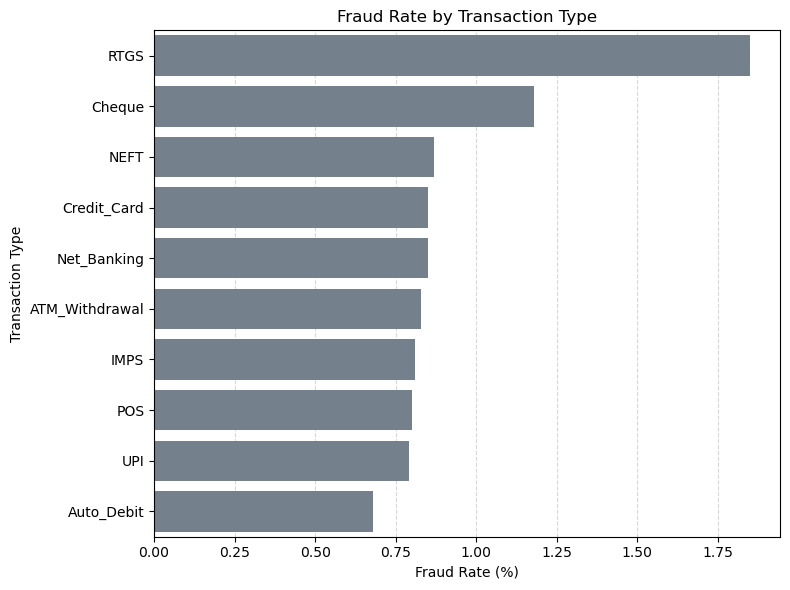

In [7]:
# Now we are just visualizing the fraud rate by transaction type using a bar plot
plt.figure(figsize=(8, 6))

sns.barplot(data=fraud_by_type.reset_index(),x="Fraud_Rate_%",y="transaction_type",color="slategray")

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Type")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()


#### Observations

- we found that the RTGS has the highest fraud rate which is  1.85%, followed by Cheque which has 1.18%.
- in our datat UPI has the highest number of fraud-labeled transactions, with 1,211 cases.
- Also the auto debit has the lowest fraud rate at 0.68%.


#### `3:-`Now we will do the Fraud Analysis by Transaction Hour


In [8]:
# Fraud analysis by hour will help us to find if there are specific hours of the day when fraud transactions happans more frequently.
fraud_by_hour = df.groupby("transaction_hour").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_hour["Fraud_Rate_%"] = (
    fraud_by_hour["Fraud_Transactions"] /
    fraud_by_hour["Total_Transactions"] * 100
).round(2)

print(fraud_by_hour)

                  Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_hour                                                      
0                              22928                 217          0.95
1                              23017                 182          0.79
2                              22740                 192          0.84
3                              22886                 211          0.92
4                              23082                 202          0.88
5                              22514                 193          0.86
6                              22931                 213          0.93
7                              22982                 218          0.95
8                              23242                 197          0.85
9                              22659                 202          0.89
10                             23111                 233          1.01
11                             23062                 196          0.85
12    

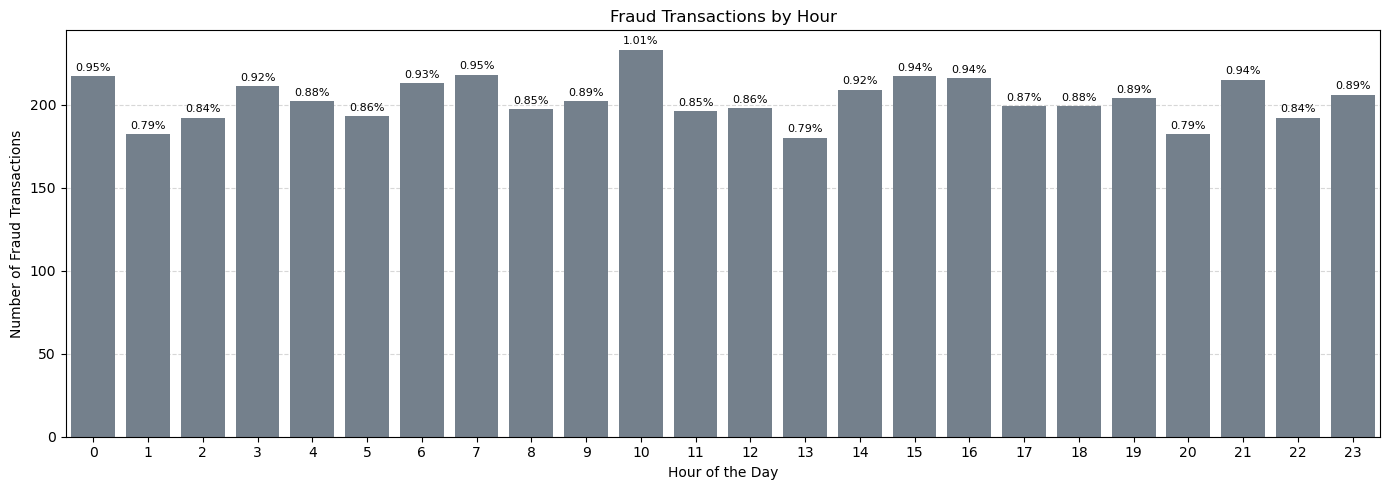

In [9]:
#now we are just visualizing the fraud rate by hour using a bar plot
plt.figure(figsize=(14,5))

ax = sns.barplot(data=fraud_by_hour.reset_index(),x="transaction_hour",y="Fraud_Transactions",color="slategray")

# just A=adding fraud rate percentage above each bar
for i, bar in enumerate(ax.patches):
    height = bar.get_height()
    hour = int(bar.get_x() + bar.get_width() / 2)

    fraud_rate = fraud_by_hour.loc[hour, "Fraud_Rate_%"]

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{fraud_rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.title("Fraud Transactions by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(range(0, 24))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Highest fraud rate:** found at 10 AM, with a fraud rate of 1.01% and 233 fraud-labeled transactions.
- **Lowest fraud rate:** found at 1 AM, 1 PM, and 8 PM, each with a fraud rate of 0.79%.
- and also Fraud rates remain relatively consistent throughout the day, ranging from 0.79% to 1.01%.

#### `4:-`Now we will do Fraud Analysis by Transaction Status

In [10]:
# This will help us find whether fraud-labeled transactions occur more frequently among successful, failed, reversed, or pending transactions.
fraud_by_status = df.groupby("transaction_status").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_status["Fraud_Rate_%"] = (
    fraud_by_status["Fraud_Transactions"]
    / fraud_by_status["Total_Transactions"] * 100
).round(2)

fraud_by_status = fraud_by_status.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_status)

                    Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_status                                                      
Pending                          10829                 103          0.95
Failed                           21905                 205          0.94
Reversed                         11019                 100          0.91
Success                         506247                4465          0.88


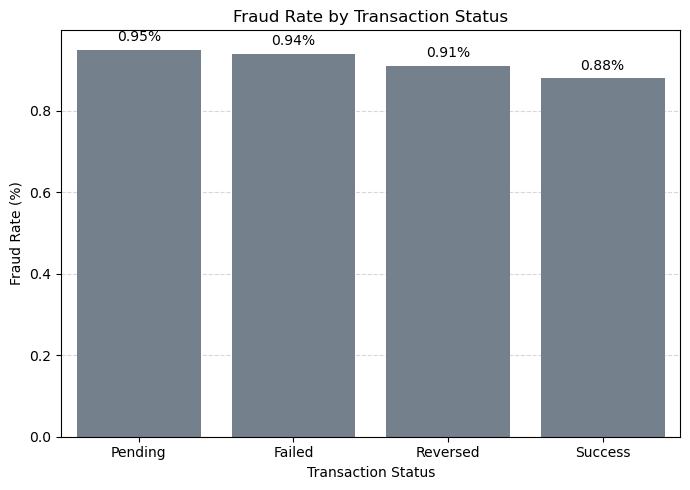

In [11]:
# Now we are just visualizing
plt.figure(figsize=(7, 5))

ax = sns.barplot(data=fraud_by_status.reset_index(),x="transaction_status",y="Fraud_Rate_%",color='slategray')

# just Add percentage labels above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Transaction Status")
plt.xlabel("Transaction Status")
plt.ylabel("Fraud Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation
- **Highest fraud rate:** found in the  Pending transactions, with a fraud rate of 0.95% (103 fraud-labeled transactions).
- **Failed transactions:** Have a fraud rate of 0.94%, with 205 fraud-labeled transactions.
- **Reversed transactions:** Have a fraud rate of 0.91%, with 100 fraud-labeled transactions.
- **Successful transactions:** Have the lowest fraud rate at 0.88%,
- But the **Successful transactions** has the the highest number of fraud-labeled transactions which is ` 4,465`due to their large transaction volume.

#### `5:-`Now we will do the Fraud Analysis by Account Type

In [12]:
# It will help us to understand whether fraud rates differ between Savings, Current, Salary, NRI, and Fixed Deposit accounts.
fraud_by_account = df.groupby("account_type").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_account["Fraud_Rate_%"] = (
    fraud_by_account["Fraud_Transactions"]
    / fraud_by_account["Total_Transactions"] * 100
).round(2)

fraud_by_account = fraud_by_account.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_account)

               Total_Transactions  Fraud_Transactions  Fraud_Rate_%
account_type                                                       
Savings                    219651                2002          0.91
NRI                         43746                 390          0.89
Fixed Deposit               38888                 344          0.88
Current                    137648                1196          0.87
Salary                     110067                 941          0.85


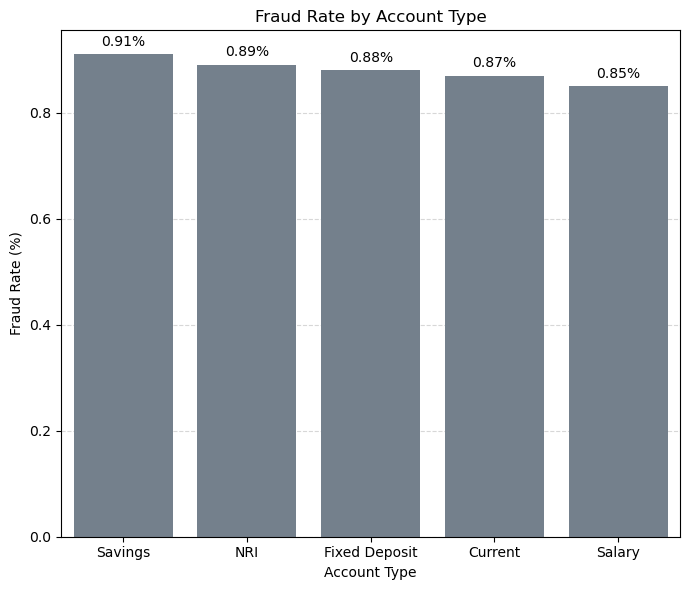

In [13]:
#Now we are just visualizing it
plt.figure(figsize=(7, 6))

ax = sns.barplot(data=fraud_by_account.reset_index(),x="account_type",y="Fraud_Rate_%",color='slategray')

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Fraud Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation
- **Highest fraud rate:** found in thr  Savings accounts, with a fraud rate of 0.91% and 2,002 fraud-labeled transactions.
- **NRI accounts:** Have a fraud rate of 0.89%, with 390 fraud-labeled transactions.
- **Fixed Deposit accounts:** Have a fraud rate of 0.88%, with 344 fraud-labeled transactions.
- **Current accounts:** Have a fraud rate of 0.87%, with 1,196 fraud-labeled transactions.
- **Lowest fraud rate:** Salary accounts, at 0.85%, with 941 fraud-labeled transactions.

#### `6:-` Now we will do Fraud Analysis by Transaction Amount

In [14]:
# Now we will see the minimum,maximum and the average of the fraud amount
fraud_amount_summary = df.groupby("is_fraud")[
    "transaction_amount"
].agg(["count", "mean", "median", "min", "max"])

print(fraud_amount_summary)

           count           mean   median   min          max
is_fraud                                                   
0         545127   29106.685733  2030.99  2.40  10000000.00
1           4873  119446.211798  2691.95  8.65   6751663.36


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


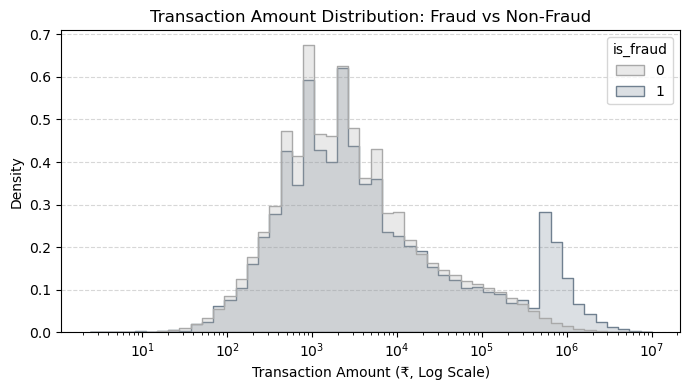

In [15]:
# now we are going to visualize it
plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="transaction_amount",
    hue="is_fraud",
    bins=50,log_scale=True,element="step",stat="density",common_norm=False,palette=["darkgray", "slategray"]
)

plt.title("Transaction Amount Distribution: Fraud vs Non-Fraud")
plt.xlabel("Transaction Amount (₹, Log Scale)")
plt.ylabel("Density")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation

- **Average transaction amount:** found in Fraud-labeled transactions have a higher average amount (1,19,446.21) than non-fraud transactions (29,106.69).
- **Median transaction amount:** found in Fraud-labeled transactions have a median amount of 2,691.95, compared with 2,030.99 for non-fraud transactions.
- **Minimum amount:** found in Fraud-labeled transactions start at 8.65, while non-fraud transactions start at 2.40.
- **Maximum amount:** The highest fraud-labeled transaction amount is 67,51,663.36, while the highest non-fraud transaction amount is 1,00,00,000.

#### `7:-`Now we will do Fraud Analysis by Transaction Direction.

In [16]:
# it will help us to find which direction has the highest fraud rate dabit or credit
fraud_by_direction = df.groupby("transaction_direction").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_direction["Fraud_Rate_%"] = (
    fraud_by_direction["Fraud_Transactions"]
    / fraud_by_direction["Total_Transactions"] * 100
).round(2)

fraud_by_direction = fraud_by_direction.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_direction)

                       Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_direction                                                      
Credit                             179606                1646          0.92
Debit                              370394                3227          0.87


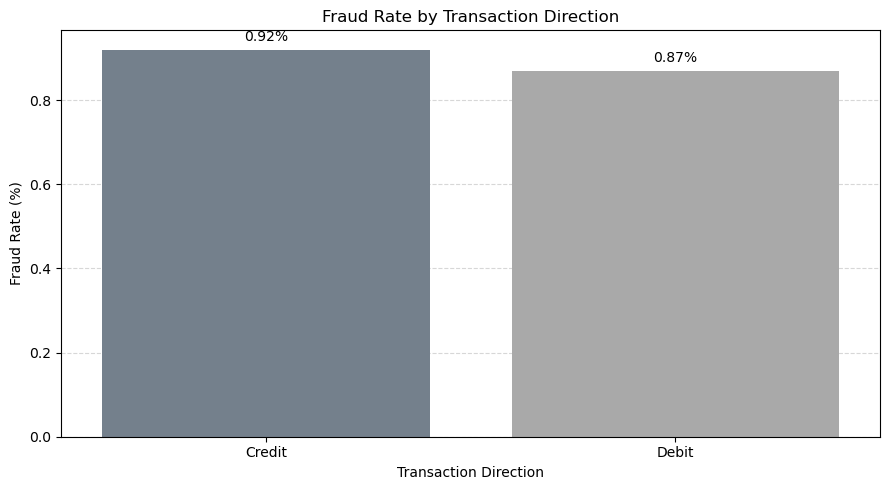

In [17]:
# now we will jsut vizulize it
# plt.figure(figsize=(8, 5))

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=fraud_by_direction.reset_index(),
    x="transaction_direction",
    y="Fraud_Rate_%",
    hue="transaction_direction",
    hue_order=["Credit", "Debit"],
    palette=["slategray", "darkgray"],
    legend=False
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Transaction Direction")
plt.xlabel("Transaction Direction")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### observation
- **Credit transactions:** Have a fraud rate of 0.92%, with 1,646 fraud-labeled transactions.
- **Debit transactions:** Have a fraud rate of 0.87%, with 3,227 fraud-labeled transactions.
- **Higher fraud rate:** Credit transactions have a slightly higher fraud rate than debit transactions.

#### `8:-`Now we will do fraud Analysis by Merchant Category.

In [18]:
# It will help us identify which merchant categories have higher fraud rates, such as Utilities, Food & Dining, and E-Commerce
fraud_by_merchant = df.groupby("merchant_category").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_merchant["Fraud_Rate_%"] = (
    fraud_by_merchant["Fraud_Transactions"]
    / fraud_by_merchant["Total_Transactions"] * 100
).round(2)

fraud_by_merchant = fraud_by_merchant.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_merchant)

                   Total_Transactions  Fraud_Transactions  Fraud_Rate_%
merchant_category                                                      
Peer Transfer                   38753                 362          0.93
E-Commerce                      54767                 502          0.92
Fuel                            21929                 201          0.92
Investment                      27380                 252          0.92
Entertainment                   32997                 300          0.91
Healthcare                      33015                 300          0.91
Retail                          66180                 594          0.90
Salary                          43937                 396          0.90
Travel                          44177                 388          0.88
Insurance                       22020                 191          0.87
Education                       27359                 236          0.86
Food & Dining                   54776                 471       

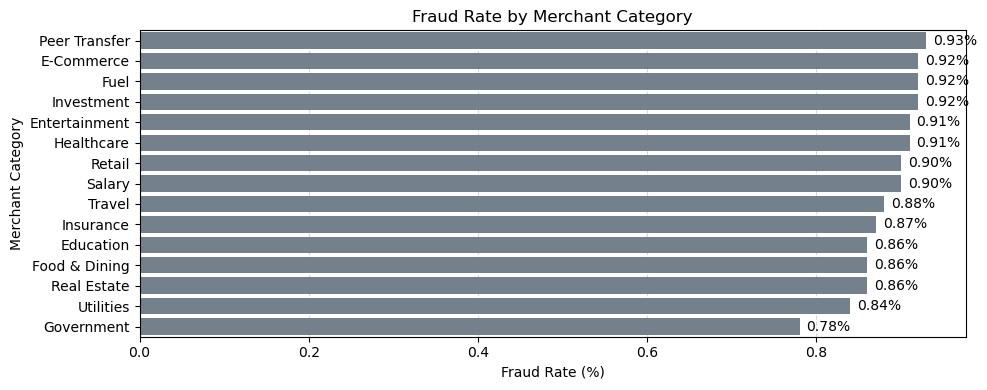

In [19]:
# just visualizing our findings using a bar plot
plt.figure(figsize=(10, 4))

ax = sns.barplot(
    data=fraud_by_merchant.reset_index(),
    x="Fraud_Rate_%",
    y="merchant_category",
    color="slategray"
)

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Merchant Category")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Highest fraud rate:** found in Peer Transfer (person to person in our data), at 0.93%, with 362 fraud-labeled transactions.
- **E-Commerce, Fuel, and Investment:** Each has a fraud rate of around 0.92%.
- **Highest fraud count by volume:** found in Retail has the most fraud-labeled transactions, with 594 cases.
- **Lowest fraud rate:** found in Government transactions, at 0.78%, with 214 cases.
t.

#### `9:-` Now we do Fraud Analysis by Transaction Channel.

In [20]:
# Now we will  compare channels such as Mobile App, Web, ATM, and POS Terminal to see how fraud rates differ.
fraud_by_channel = df.groupby("channel").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_channel["Fraud_Rate_%"] = (
    fraud_by_channel["Fraud_Transactions"]
    / fraud_by_channel["Total_Transactions"] * 100
).round(2)

fraud_by_channel = fraud_by_channel.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_channel)

              Total_Transactions  Fraud_Transactions  Fraud_Rate_%
channel                                                           
Branch                     54957                 520          0.95
POS_Terminal               60853                 557          0.92
API                        38635                 346          0.90
Web                       121010                1080          0.89
Mobile_App                208368                1809          0.87
ATM                        66177                 561          0.85


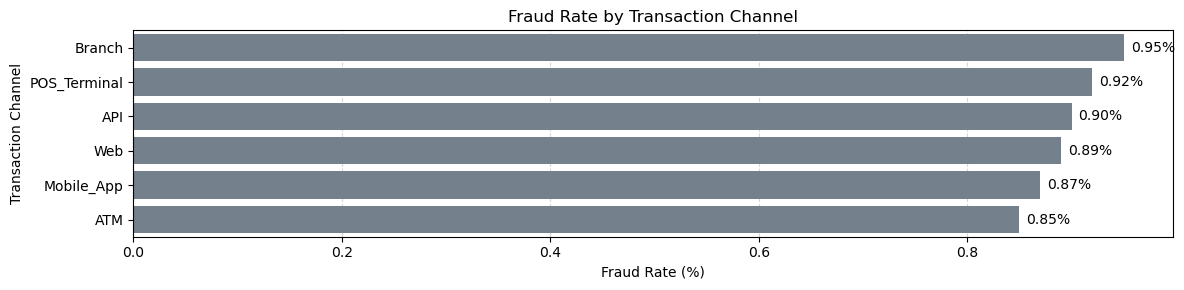

In [21]:
# Now we are just visualizing the fraud rate by transaction channel using a bar plot
plt.figure(figsize=(12, 3))

ax = sns.barplot(
    data=fraud_by_channel.reset_index(),
    x="Fraud_Rate_%",
    y="channel",
    color="slategray"
)

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.title("Fraud Rate by Transaction Channel")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Channel")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Highest fraud rate:** found in Branch transactions, at 0.95%, with 520 fraud-labeled transactions.
- **POS Terminal:** Has a fraud rate of 0.92%, with 557 fraud-labeled transactions.
- **Highest fraud count as per the volume:** found at Mobile App transactions have the most fraud-labeled transactions, with 1,809 cases.
- **Lowest fraud rate:** found at ATM transactions, at 0.85%, with 561 fraud-labeled transactions.

#### `10:-`Now we will do fraud Analysis by KYC Status.

In [23]:
#Now we will investigate whether fraud rates differ between Verified, Pending, and Expired KYC statuses.
fraud_by_kyc = df.groupby("kyc_status").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_kyc["Fraud_Rate_%"] = (
    fraud_by_kyc["Fraud_Transactions"]
    / fraud_by_kyc["Total_Transactions"] * 100
).round(2)

fraud_by_kyc = fraud_by_kyc.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_kyc)

            Total_Transactions  Fraud_Transactions  Fraud_Rate_%
kyc_status                                                      
Pending                  44288                 392          0.89
Verified                483457                4293          0.89
Expired                  22255                 188          0.84


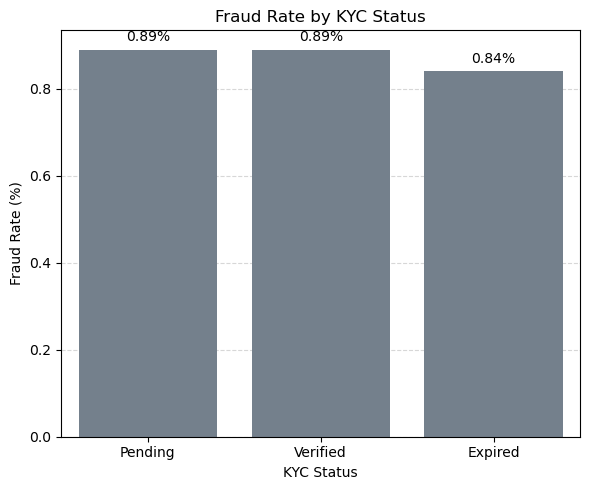

In [27]:
# Now we are just visualizing the fraud rate by KYC status using a bar plot
plt.figure(figsize=(6, 5))

ax = sns.barplot(
    data=fraud_by_kyc.reset_index(),
    x="kyc_status",
    y="Fraud_Rate_%",
    color="slategray"
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by KYC Status")
plt.xlabel("KYC Status")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations

- **Pending KYC:** Has a fraud rate of 0.89%, with 392 fraud-labeled transactions.
- **Verified KYC:** Also has a fraud rate of 0.89%, with 4,293 fraud-labeled transactions.
- **Expired KYC:** Has the lowest fraud rate at 0.84%, with 188 fraud-labeled transactions.

#### `11:-`Now we will fraud Analysis by Credit Score.

In [29]:
# Now we will investigate whether fraud rates differ among customers with low, medium, and high credit scores
df["credit_score_category"] = pd.cut(
    df["credit_score"],
    bins=[299, 499, 699, 899],
    labels=["Low", "Medium", "High"]
)

In [30]:
# now we will calculate the fraud rate for each credit score category
fraud_by_credit = df.groupby(
    "credit_score_category",
    observed=True
).agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_credit["Fraud_Rate_%"] = (
    fraud_by_credit["Fraud_Transactions"]
    / fraud_by_credit["Total_Transactions"] * 100
).round(2)

print(fraud_by_credit)

                       Total_Transactions  Fraud_Transactions  Fraud_Rate_%
credit_score_category                                                      
Low                                182799                1586          0.87
Medium                             183989                1653          0.90
High                               183212                1634          0.89


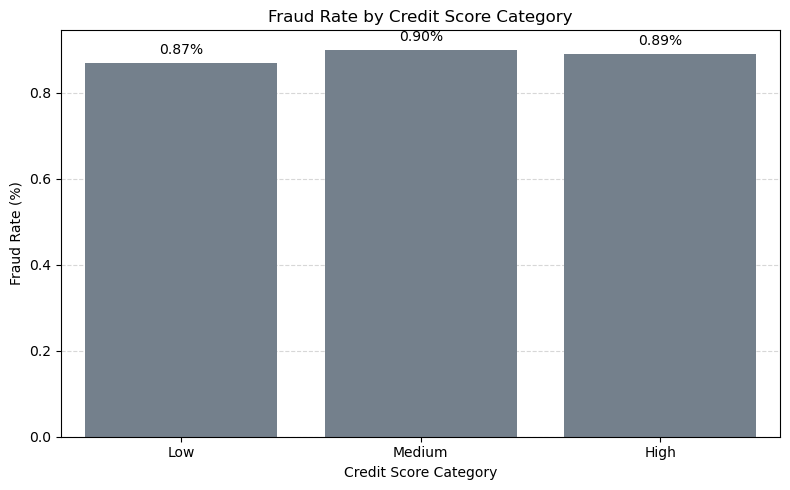

In [34]:
#now we will visualize it
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=fraud_by_credit.reset_index(),
    x="credit_score_category",
    y="Fraud_Rate_%",
    color="slategray"
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Credit Score Category")
plt.xlabel("Credit Score Category")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Low Credit Score (300–499):** Has a fraud rate of 0.87%, with 1,586 fraud-labeled transactions.
- **Medium Credit Score (500–699):** Has the highest fraud rate of 0.90%, with 1,653 fraud-labeled transactions.
- **High Credit Score (700–899):** Has a fraud rate of 0.89%, with 1,634 fraud-labeled transactions.

#### `12:-`Now we will do fraud Analysis by Account Balance.

In [40]:
# now we will investigate whether fraud rates differ depending on the account balance available during a transaction.
df["balance_category"] = pd.cut(
    df["account_balance"],
    bins=[0, 25000, 100000, float("inf")],
    labels=["Low", "Medium", "High"]
)

In [36]:
# now we will calculate fraud count and rates
fraud_by_balance = df.groupby(
    "balance_category",
    observed=True
).agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_balance["Fraud_Rate_%"] = (
    fraud_by_balance["Fraud_Transactions"]
    / fraud_by_balance["Total_Transactions"] * 100
).round(2)

print(fraud_by_balance)

                  Total_Transactions  Fraud_Transactions  Fraud_Rate_%
balance_category                                                      
Low                           212559                1918          0.90
Medium                        217139                1833          0.84
High                          120302                1122          0.93


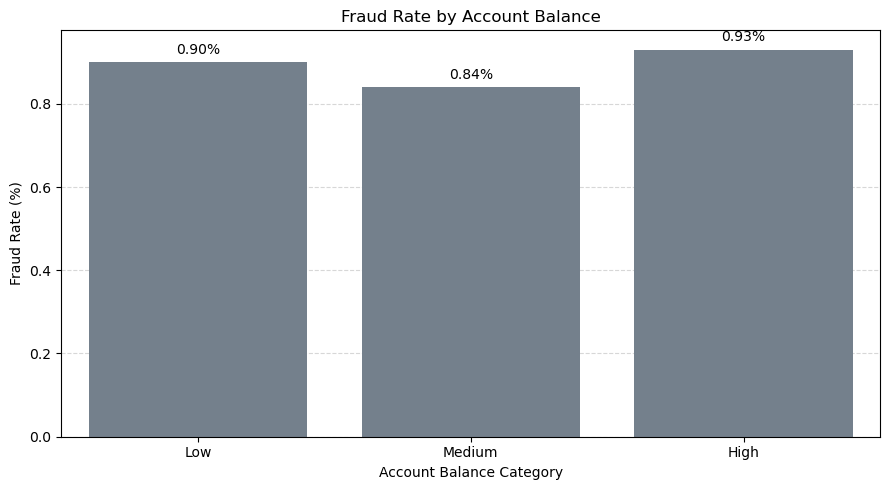

In [39]:
# now we will visualize it
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=fraud_by_balance.reset_index(),
    x="balance_category",
    y="Fraud_Rate_%",
    color="slategray"
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Account Balance")
plt.xlabel("Account Balance Category")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Low Balance:** accounts has a fraud rate of 0.90%, with 1,918 fraud-labeled transactions.
- **Medium Balance:** accounts has the lowest fraud rate at 0.84%, with 1,833 fraud-labeled transactions.
- **High Balance:** accouts has the highest fraud rate at 0.93%, with 1,122 fraud-labeled transactions.

#### `13`:- Now we will do fraud Analysis by Loan Status

In [41]:
# We will compare customers who have loans with customers who do not have loans.
fraud_by_loan = df.groupby("has_loan").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_loan["Fraud_Rate_%"] = (
    fraud_by_loan["Fraud_Transactions"] /
    fraud_by_loan["Total_Transactions"] * 100
).round(2)

fraud_by_loan.index = fraud_by_loan.index.map({
    0: "No Loan",
    1: "Has Loan"
})

fraud_by_loan.index.name = "Loan_Status"

print(fraud_by_loan)

             Total_Transactions  Fraud_Transactions  Fraud_Rate_%
Loan_Status                                                      
No Loan                  357712                3146          0.88
Has Loan                 192288                1727          0.90


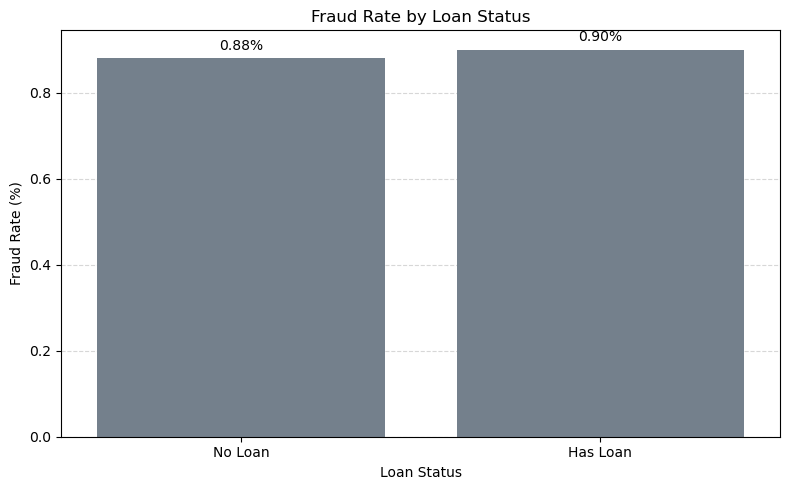

In [42]:
# now we will visualize it
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=fraud_by_loan.reset_index(),
    x="Loan_Status",
    y="Fraud_Rate_%",
    color="slategray"
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations

- **Customers with loans:** have a fraud rate of 0.90%, with 1,727 fraud-labeled transactions.
- **Customers without loans:** have a fraud rate of 0.88%, with 3,146 fraud-labeled transactions.
- Customers without loans have a higher number of fraud-labeled transactions because their total transaction volume is larger.

##### `14:-`Now we will do the fraud Analysis by Loan Type

In [44]:
# Now we will investigate whether fraud rates differ among customers with different types of loans.
fraud_by_loan_type = df.groupby("loan_type").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_loan_type["Fraud_Rate_%"] = (
    fraud_by_loan_type["Fraud_Transactions"]
    / fraud_by_loan_type["Total_Transactions"] * 100
).round(2)

fraud_by_loan_type = fraud_by_loan_type.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_loan_type)

                   Total_Transactions  Fraud_Transactions  Fraud_Rate_%
loan_type                                                              
Gold                             9648                  97          1.01
Loan Type Unknown               19422                 190          0.98
Business                        28863                 274          0.95
Auto                            29219                 263          0.90
Home                            38252                 339          0.89
Education                       19074                 167          0.88
No Loan                        357712                3146          0.88
Personal                        47810                 397          0.83


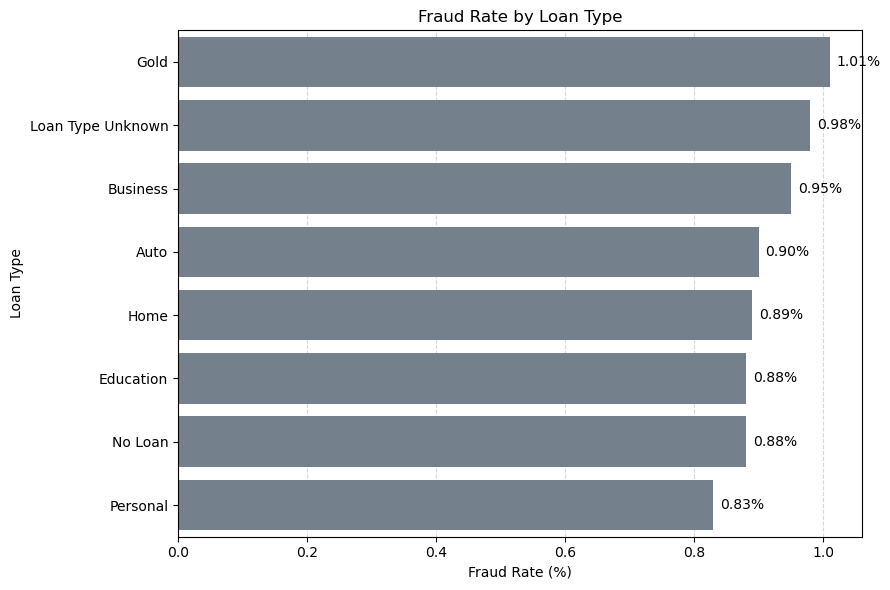

In [47]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=fraud_by_loan_type.reset_index(),
    x="Fraud_Rate_%",
    y="loan_type",
    color="slategray"
)

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.title("Fraud Rate by Loan Type")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Loan Type")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations

- **Gold Loan:** Has the highest fraud rate at 1.01%, with 97 fraud-labeled transactions.
- **Loan Type Unknown:** Has a fraud rate of 0.98%, with 190 fraud-labeled transactions.
- **Business Loan:** Has a fraud rate of 0.95%, with 274 fraud-labeled transactions.
- **Highest fraud count:** No Loan has the highest number of fraud-labeled transactions, with 3,146 cases.
- **Personal Loan:** Has the lowest fraud rate at 0.83%, with 397 fraud-labeled transactions.
- Fraud rates vary across different loan types, ranging from 0.83% to 1.01%.


`15:-`Now we will do the fraud Analysis by State

In [48]:
# Now we will identify which Indian states have higher fraud rates and which states account for more fraud-labeled transactions.
fraud_by_state = df.groupby("state").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_state["Fraud_Rate_%"] = (
    fraud_by_state["Fraud_Transactions"]
    / fraud_by_state["Total_Transactions"] * 100
).round(2)

fraud_by_state = fraud_by_state.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_state)

             Total_Transactions  Fraud_Transactions  Fraud_Rate_%
state                                                            
UP                        27414                 260          0.95
West Bengal               43950                 413          0.94
Karnataka                 76659                 701          0.91
Delhi                     66114                 588          0.89
Maharashtra               98911                 885          0.89
Telangana                 49610                 440          0.89
Gujarat                   54798                 482          0.88
Tamil Nadu                71747                 633          0.88
Rajasthan                 38725                 303          0.78
Punjab                    22072                 168          0.76


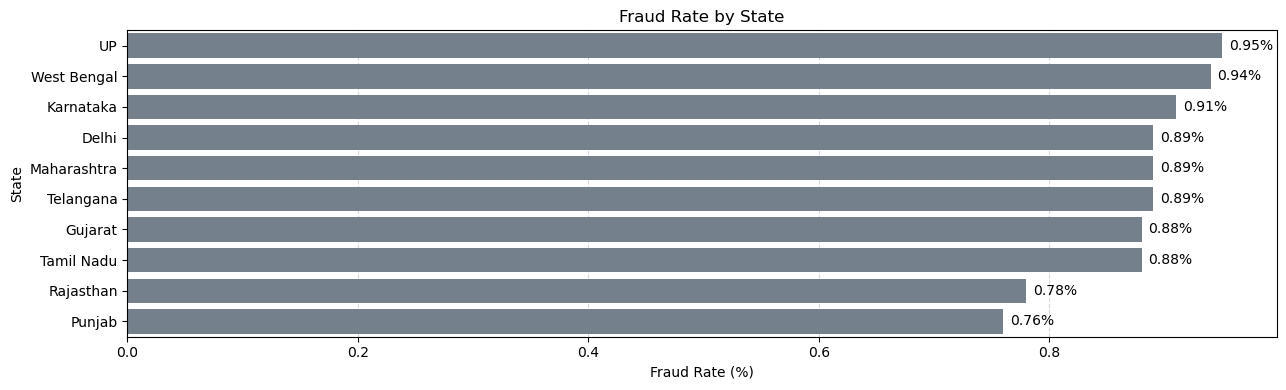

In [56]:
# no we will visualize it
plt.figure(figsize=(13, 4))
ax = sns.barplot(
    data=fraud_by_state.reset_index(),
    x="Fraud_Rate_%",
    y="state",
    color="slategray"
)

for bar in ax.patches:
    width = bar.get_width()

    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.title("Fraud Rate by State")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("State")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Highest fraud rate:** found in uttar Pradesh (UP), at 0.95%, with 260 fraud-labeled transactions.
- **West Bengal:** Has a fraud rate of 0.94%, with 413 fraud-labeled transactions.
- **Highest fraud count by volume:** Maharashtra has the most fraud-labeled transactions, with 885 cases.
- **Karnataka:** Has 701 fraud-labeled transactions, with a fraud rate of 0.91%.
- **Lowest fraud rate:** found at punjab, at 0.76%, with 168 fraud-labeled transactions.

#### `16:-`Now we aill do Correlation Analysis

In [57]:
# Correlation analysis will help us to understand how numerical variables are related to each other and whether they have any noticeable relationship with the fraud labe.
numerical_df = df[
    [
        "transaction_amount",
        "account_balance",
        "credit_score",
        "emi_amount",
        "transaction_hour",
        "is_fraud"
    ]
]

In [58]:
# now we will Calculate the correlation matrix
correlation_matrix = numerical_df.corr()

print(correlation_matrix)

                    transaction_amount  account_balance  credit_score  \
transaction_amount            1.000000        -0.001393      0.000680   
account_balance              -0.001393         1.000000      0.002056   
credit_score                  0.000680         0.002056      1.000000   
emi_amount                   -0.000295        -0.001352      0.001762   
transaction_hour             -0.001188         0.001455      0.000581   
is_fraud                      0.060638         0.001734      0.000186   

                    emi_amount  transaction_hour  is_fraud  
transaction_amount   -0.000295         -0.001188  0.060638  
account_balance      -0.001352          0.001455  0.001734  
credit_score          0.001762          0.000581  0.000186  
emi_amount            1.000000          0.001842  0.001489  
transaction_hour      0.001842          1.000000 -0.000264  
is_fraud              0.001489         -0.000264  1.000000  


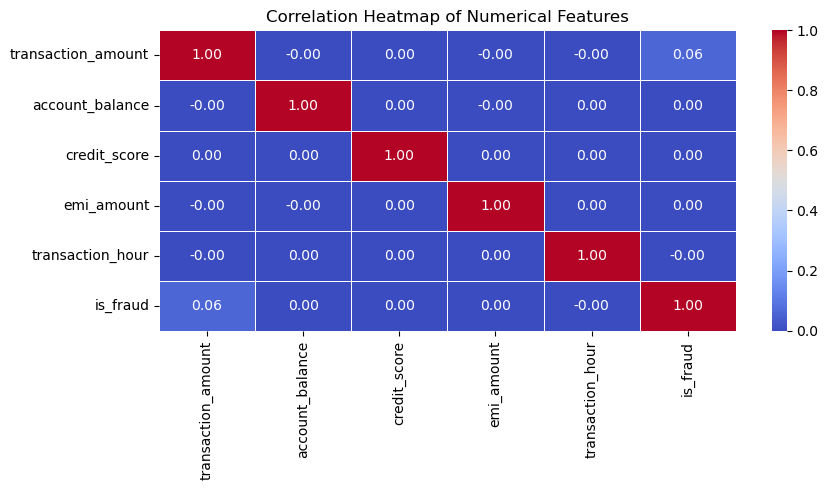

In [61]:
# now we will visualize using a heat map
plt.figure(figsize=(9, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

#### Observations

- **Transaction Amount:** Shows a weak positive correlation (0.06) with fraud.
- **Account Balance:** Shows almost no correlation with fraud (0.0017).
- **Credit Score:** Shows almost no correlation with fraud (0.0002).
- **EMI Amount:** Shows almost no correlation with fraud (0.0015).
- **Transaction Hour:** Shows almost no correlation with fraud (-0.0003).
- Most numerical features have very weak correlations with each other.

#### # Final Exploratory Data Analysis Summary

#### 1. Dataset Overview

- Total transactions analyzed:**550,000**
- Non-fraud transactions:**545,127 (99.11%)**
- Fraud-labeled transactions: **4,873 (0.89%)**
- Total features: **20 columns**

The dataset is highly imbalanced, as fraud-labeled transactions account for less than 1% of all transactions.

#### 2. Key Findings

#### Transaction Analysis
- RTGS has the highest fraud rate among transaction types at **1.85%**.
- 10 AM has the highest hourly fraud rate at **1.01%**.
- Pending transactions have the highest fraud rate by transaction status at **0.95%**.
- Credit transactions have a slightly higher fraud rate (**0.92%**) than debit transactions (**0.87%**).

#### Customer and Account Analysis
- Savings accounts have the highest fraud rate at **0.91%**.
- High-balance transactions have the highest fraud rate at **0.93%**.
- Customers with loans have a slightly higher fraud rate (**0.90%**) than customers without loans (**0.88%**).
- Medium credit score customers have the highest fraud rate at **0.90%**.

#### Merchant and Channel Analysis
- Peer Transfer has the highest fraud rate among merchant categories at **0.93%**.
- Branch transactions have the highest fraud rate among transaction channels at **0.95%**.
- Retail has the highest number of fraud-labeled transactions among merchant categories, with **594 cases**.
- Mobile App transactions have the highest number of fraud-labeled transactions among channels, with **1,809 cases**.

#### Loan and KYC Analysis
- Gold Loan has the highest fraud rate among loan types at **1.01%**.
- Pending and Verified KYC transactions both have a fraud rate of **0.89%**.
- Expired KYC transactions have the lowest fraud rate at **0.84%**.

#### Geographical Analysis
- Uttar Pradesh has the highest state-level fraud rate at **0.95%**.
- Maharashtra has the highest number of fraud-labeled transactions, with **885 cases**.
- Punjab has the lowest state-level fraud rate at **0.76%**.

#### Transaction Amount Analysis
- Average fraud-labeled transaction amount: **₹1,19,446.21**.
- Average non-fraud transaction amount: **₹29,106.69**.
- Median fraud-labeled transaction amount: **₹2,691.95**.
- Median non-fraud transaction amount: **₹2,030.99**.

Fraud-labeled transactions have higher average and median amounts than non-fraud transactions.

#### 3. Correlation Analysis

- Transaction amount has the strongest positive correlation with fraud among the numerical features, at **0.06**.
- Account balance, credit score, EMI amount, and transaction hour show almost no linear correlation with the fraud label.
- Most numerical variables have very weak correlations with each other.